In [1]:
import os
import torch
import timm
import numpy as np
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from torchvision import transforms


e:\semester7\comvis\deteksidaun\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ===== PATH =====
PROJECT_ROOT = r"E:\semester7\comvis\deteksidaun"
TEST_DIR   = os.path.join(PROJECT_ROOT, "dataset/split/test")
MODEL_PATH = os.path.join(PROJECT_ROOT, "models/best_model.pth")
CLASSES_PATH = os.path.join(PROJECT_ROOT, "models/classes.pt")

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)



Device: cuda


In [3]:
# ===== LOAD CLASSES =====
classes = torch.load(CLASSES_PATH, weights_only=True) if "weights_only" in torch.load.__code__.co_varnames else torch.load(CLASSES_PATH)
num_classes = len(classes)
print("Classes:", classes)



Classes: ['Bercak Daun', 'Daun Sehat', 'Hawar Daun', 'Karat Daun']


In [4]:
# ===== TRANSFORM TEST (sama kayak val) =====
mean, std = [0.485,0.456,0.406], [0.229,0.224,0.225]
test_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])



In [5]:
# ===== DATASET/LOADER =====
test_ds = ImageFolder(TEST_DIR, transform=test_tf)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=0)



In [6]:
# ===== MODEL =====
model = timm.create_model("convnext_small", pretrained=False, num_classes=num_classes)
state = torch.load(MODEL_PATH, map_location=device)
model.load_state_dict(state)
model.to(device)
model.eval()



C:\Users\HP\AppData\Local\Temp\ipykernel_5960\3695939577.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(MODEL_PATH, map_location=device)


ConvNeXt(
  (stem): Sequential(
    (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
    (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
  )
  (stages): Sequential(
    (0): ConvNeXtStage(
      (downsample): Identity()
      (blocks): Sequential(
        (0): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (norm): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (mlp): Mlp(
            (fc1): Linear(in_features=96, out_features=384, bias=True)
            (act): GELU()
            (drop1): Dropout(p=0.0, inplace=False)
            (norm): Identity()
            (fc2): Linear(in_features=384, out_features=96, bias=True)
            (drop2): Dropout(p=0.0, inplace=False)
          )
          (shortcut): Identity()
          (drop_path): Identity()
        )
        (1): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)


In [7]:
# ===== PREDICT =====
y_true, y_pred = [], []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        logits = model(x)
        pred = logits.argmax(dim=1).cpu().numpy()
        y_pred.extend(pred.tolist())
        y_true.extend(y.numpy().tolist())

# ===== METRICS =====
acc = accuracy_score(y_true, y_pred)
cm = confusion_matrix(y_true, y_pred)
report = classification_report(y_true, y_pred, target_names=classes, digits=4)

print("\n✅ TEST Accuracy:", acc)
print("\nConfusion Matrix:\n", cm)
print("\nClassification Report:\n")
print(report)

# per-class accuracy
cm = cm.astype(np.float64)
per_class_acc = cm.diagonal() / cm.sum(axis=1)
print("\n🎯 Per-class Accuracy:")
for c, a in zip(classes, per_class_acc):
    print(f"- {c:12s}: {a:.4f}")



✅ TEST Accuracy: 0.9731012658227848

Confusion Matrix:
 [[ 78   0   8   1]
 [  0 175   0   0]
 [  6   0 167   0]
 [  0   0   2 195]]

Classification Report:

              precision    recall  f1-score   support

 Bercak Daun     0.9286    0.8966    0.9123        87
  Daun Sehat     1.0000    1.0000    1.0000       175
  Hawar Daun     0.9435    0.9653    0.9543       173
  Karat Daun     0.9949    0.9898    0.9924       197

    accuracy                         0.9731       632
   macro avg     0.9667    0.9629    0.9647       632
weighted avg     0.9731    0.9731    0.9730       632


🎯 Per-class Accuracy:
- Bercak Daun : 0.8966
- Daun Sehat  : 1.0000
- Hawar Daun  : 0.9653
- Karat Daun  : 0.9898


In [1]:
# ===== PREDICT =====
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        logits = model(x)
        pred = logits.argmax(dim=1).cpu().numpy()
        y_pred.extend(pred.tolist())
        y_true.extend(y.numpy().tolist())

# ===== METRICS =====
display_classes = ['Gray Leaf Spot', 'Healthy', 'Leaf Blight', 'Common Rust']  # tambah ini

acc = accuracy_score(y_true, y_pred)
cm = confusion_matrix(y_true, y_pred)
report = classification_report(y_true, y_pred, target_names=display_classes, digits=4)  # ganti classes → display_classes

print("\n✅ TEST Accuracy:", acc)
print("\nConfusion Matrix:\n", cm)
print("\nClassification Report:\n")
print(report)

# per-class accuracy
cm = cm.astype(np.float64)
per_class_acc = cm.diagonal() / cm.sum(axis=1)
print("\n🎯 Per-class Accuracy:")
for c, a in zip(display_classes, per_class_acc):  # ganti classes → display_classes
    print(f"- {c:20s}: {a:.4f}")

NameError: name 'torch' is not defined

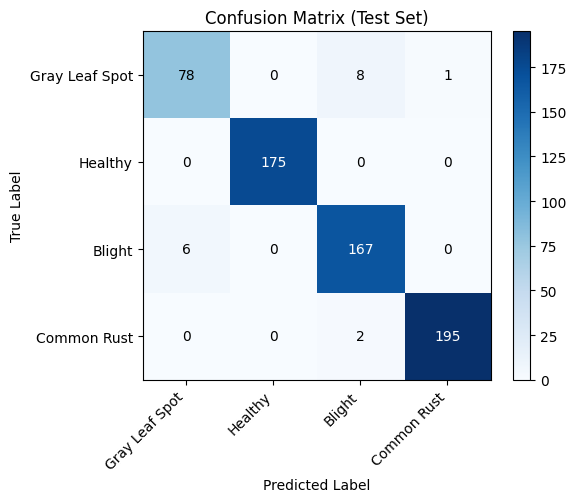

In [4]:
import numpy as np
import matplotlib.pyplot as plt

cm = np.array([
    [78, 0, 8, 1],
    [0, 175, 0, 0],
    [6, 0, 167, 0],
    [0, 0, 2, 195]
])

labels = ["Gray Leaf Spot", "Healthy", "Blight", "Common Rust"]

fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(cm, cmap="Blues")

ax.set_title("Confusion Matrix (Test Set)")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels)

# Tambahkan angka di dalam kotak
threshold = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        text_color = "white" if cm[i, j] > threshold else "black"
        ax.text(j, i, cm[i, j], ha="center", va="center", color=text_color)

fig.colorbar(im, ax=ax)
plt.tight_layout()

plt.savefig("confusion_matrix_english.png", dpi=300, bbox_inches="tight")
plt.savefig("confusion_matrix_english.pdf", bbox_inches="tight")
plt.show()